# 03 - Tugas 3: Penyempurnaan Model, Feature Engineering, & Integrasi Multimodal

Notebook ini merangkum seluruh alur eksperimen **Tugas 3 NLP** secara *reproducible* di atas base pipeline Tugas 2 ([`02_baseline_experiments.ipynb`](02_baseline_experiments.ipynb)):
1. **Tahap 1 — Perbandingan 3 Kategori Feature Extraction** (Static `FastText`, Domain-Specific `ProsusAI/finbert`, General-Purpose `BAAI/bge-small-en-v1.5` & `baai/bge-large-en-v1.5` via OpenRouter).
2. **Tahap 2A — NER Tiered Entity Weighting (`spaCy en_core_web_sm`)** dengan normalisasi bobot harian $\sum w = 1.0$ & uji sensitivitas rasio Tier 1 / Tier 2.
3. **Tahap 2B — Ablasi Feature Engineering** di atas basis terpilih (`BGE-Small`): Topic Modeling (`MiniBatchKMeans + c-TF-IDF`), EWMA Sliding Window & News Shock, serta Extended Time-Series (`22` fitur `<= T-1`).
4. **Tahap 2C — Multimodal Fusion & Studi Ablasi Lengkap (Model A vs Model B vs Model C)**: Early Fusion (`LogReg`, `XGBoost`, `LightGBM`, `LSTM`), Late Fusion (`Weighted Prob`, `Weighted Logit`, `Stacking OOF`), Hybrid `GatedMultimodalNet`, + *Threshold Tuning* di `val`.
5. **Analisis Eksploratif Wajib**: Visualisasi Ruang Embedding (`UMAP` & `t-SNE`), `SHAP` Feature Importance, Korelasi Fitur NLP vs Kurs/Volatilitas, Distribusi Error, dan Case Study Tanggal Spesifik.

> **Catatan Reproducibility & Efisiensi:** Notebook ini memuat artefak cache & hasil eksperimen yang sudah dihasilkan oleh skrip modular di `src/` (`extract_embeddings.py`, `ner_weighting.py`, `feature_engineering_t3.py`, `run_stage2b_full_experiments.py`, `analyze_tugas3.py`) sehingga tidak menjalankan ulang inferensi berat Transformer/API.

In [1]:
import json
import sys
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
from IPython.display import Image, display

ROOT = Path("..").resolve()
if str(ROOT / "src") not in sys.path:
    sys.path.insert(0, str(ROOT / "src"))

from evaluate import cm_table

RES = ROOT / "results"
FIG = RES / "figures"
DATA_PROC = ROOT / "data" / "processed"

summary = json.loads((RES / "tugas3_summary.json").read_text(encoding="utf-8"))
df_full = pd.read_parquet(DATA_PROC / "features_tugas3_full.parquet")
print(f"Dataset Tugas 3: shape={df_full.shape} | Split counts:", df_full["split"].value_counts().to_dict())
print(f"Pemenang Model C (dipilih di val): {summary['best_model_c']} ({summary['best_model_c_family']})")
print(f"  Val  : DA={summary['best_model_c_val_DA']:.4f}, F1_macro={summary['best_model_c_val_F1']:.4f}")
print(f"  Test : DA={summary['best_model_c_test_DA']:.4f}, F1_macro={summary['best_model_c_test_F1']:.4f} (tau=0.50)")
print(f"  Tuned: tau={summary['best_model_c_tau']:.2f} -> Test DA={summary['best_model_c_test_DA_tuned']:.4f}, F1_macro={summary['best_model_c_test_F1_tuned']:.4f}")

Dataset Tugas 3: shape=(1201, 368) | Split counts: {'train': 720, 'test': 241, 'val': 240}
Pemenang Model C (dipilih di val): late_prob:logreg_bge_soft384+xgb_ext (Late Fusion (Prob))
  Val  : DA=0.5792, F1_macro=0.5770
  Test : DA=0.5477, F1_macro=0.5349 (tau=0.50)
  Tuned: tau=0.48 -> Test DA=0.5477, F1_macro=0.5336


## 1. Tahap 1: Perbandingan 3 Kategori Feature Extraction (Simple Mean Pooling)
Protokol evaluasi identik dengan Tugas 2 (`XGBClassifier` dengan 7 fitur lag/vol kurs dari `src/model.py`). Untuk tiap embedding, dimensi terbaik (`pca8`, `pca16`, `pca32`, `pca50`, `raw`) dipilih **hanya berdasarkan split `val`** lalu diuji satu kali pada `test`.

In [2]:
s1_metrics = pd.read_csv(RES / "stage1_feature_extraction_metrics.csv")
s1_sweep = pd.read_csv(RES / "stage1_pca_sweep.csv")

s1_val = s1_metrics[s1_metrics["split"] == "val"].set_index("model")
s1_test = s1_metrics[s1_metrics["split"] == "test"].copy()
s1_test.insert(3, "DA_val", s1_test["model"].map(s1_val["DA"]))
s1_test.insert(4, "F1_val", s1_test["model"].map(s1_val["F1_macro"]))

cols_show = ["model", "category", "n_features", "DA_val", "F1_val", "DA", "F1_macro", "share_pred1", "p_mcnemar_vs_kurs"]
display(s1_test[cols_show].round(4).reset_index(drop=True))

,model,category,n_features,DA_val,F1_val,DA,F1_macro,share_pred1,p_mcnemar_vs_kurs
0,majority,Model A: Time-Series Baseline,1,0.5125,0.3388,0.5726,0.3641,1.0000,0.1112
1,persistence,Model A: Time-Series Baseline,1,0.5417,0.5414,0.5311,0.5204,0.5768,0.8496
2,arima,Model A: Time-Series Baseline,1,0.5417,0.5370,0.5436,0.5185,0.6556,0.6137
3,xgb:kurs,Model A: Time-Series Baseline,7,0.5250,0.4587,0.5187,0.4574,0.7635,1.0000
4,xgb:kurs+lexicon,Model B: NLP Dasar (Tugas 2),14,0.5750,0.5379,0.5394,0.4915,0.7344,0.5966
5,xgb:kurs+tfidf,Model B: NLP Dasar (Tugas 2),57,0.5292,0.4989,0.5021,0.4787,0.6390,0.7202
6,xgb:kurs+lexicon+tfidf,Model B: NLP Dasar (Tugas 2),64,0.5708,0.5592,0.4855,0.4716,0.5892,0.4160
7,xgb:kurs+fasttext (pca32_val_best),Kategori A: Static (FastText),39,0.5917,0.5852,0.5062,0.4736,0.6763,0.8199
8,xgb:kurs+fasttext (raw_100d),Kategori A: Static (FastText),107,0.5333,0.5171,0.5270,0.4598,0.7801,0.9088
9,xgb:kurs+finbert_emb (raw_val_best),Kategori B: Domain (FinBERT Emb),775,0.5708,0.5522,0.5353,0.4793,0.7552,0.7520


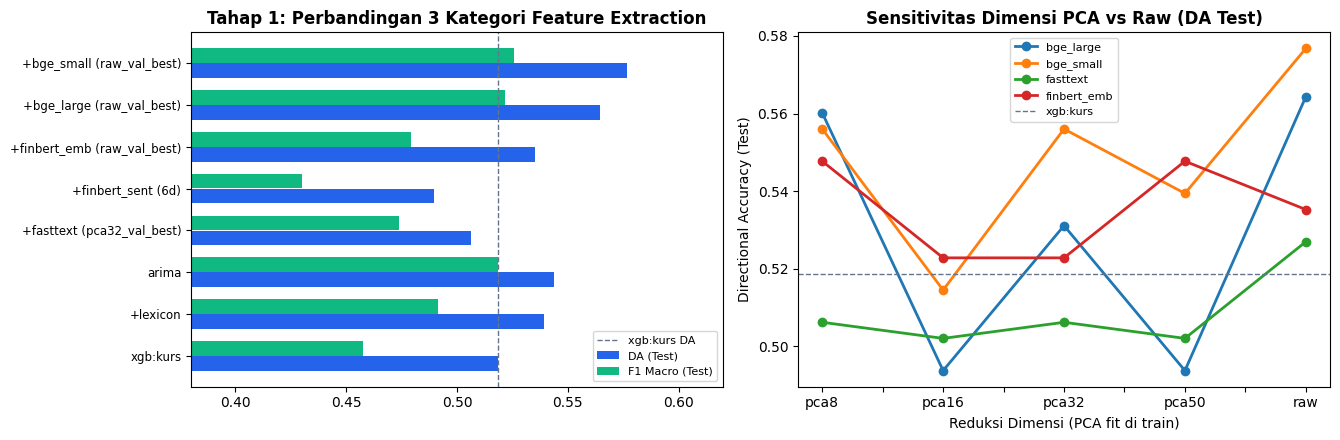

In [3]:
fig, axes = plt.subplots(1, 2, figsize=(13.5, 4.5))

# Panel kiri: Perbandingan perwakilan 3 kategori vs baseline Tugas 2
rep_models = [
    "xgb:kurs", "xgb:kurs+lexicon", "arima",
    "xgb:kurs+fasttext (pca32_val_best)",
    "xgb:kurs+finbert_sent (6d)",
    "xgb:kurs+finbert_emb (raw_val_best)",
    "xgb:kurs+bge_large (raw_val_best)",
    "xgb:kurs+bge_small (raw_val_best)",
]
sub = s1_test[s1_test["model"].isin(rep_models)].set_index("model").loc[rep_models]
y_pos = np.arange(len(sub))
axes[0].barh(y_pos - 0.18, sub["DA"], height=0.35, color="#2563EB", label="DA (Test)")
axes[0].barh(y_pos + 0.18, sub["F1_macro"], height=0.35, color="#10B981", label="F1 Macro (Test)")
axes[0].set_yticks(y_pos)
axes[0].set_yticklabels([m.replace("xgb:kurs+", "+") for m in sub.index], fontsize=8.5)
axes[0].axvline(sub.loc["xgb:kurs", "DA"], color="#64748B", ls="--", lw=1, label="xgb:kurs DA")
axes[0].set_xlim(0.38, 0.62)
axes[0].set_title("Tahap 1: Perbandingan 3 Kategori Feature Extraction", fontweight="bold")
axes[0].legend(fontsize=8)

# Panel kanan: PCA Sweep (test DA per dimensi)
piv = s1_sweep.pivot(index="dim_setting", columns="embedding", values="test_DA").loc[["pca8", "pca16", "pca32", "pca50", "raw"]]
piv.plot(ax=axes[1], marker="o", linewidth=2)
axes[1].axhline(0.5187, color="#64748B", ls="--", lw=1, label="xgb:kurs")
axes[1].set_title("Sensitivitas Dimensi PCA vs Raw (DA Test)", fontweight="bold")
axes[1].set_ylabel("Directional Accuracy (Test)")
axes[1].set_xlabel("Reduksi Dimensi (PCA fit di train)")
axes[1].legend(fontsize=8)

plt.tight_layout()
plt.show()

**Temuan Tahap 1:** **`BAAI/bge-small-en-v1.5` (`384D`)** menjadi pemenang paling jelas (**DA test = `0.5768`**, **F1 macro = `0.5258`**), mengungguli Model A (`xgb:kurs`: `0.5187`), Model B (`xgb:kurs+lexicon`: `0.5394`), FastText (`0.5062` best-val / `0.5270` raw), FinBERT (`0.5353`), maupun `bge_large` (`0.5643`). Oleh karena itu, **`bge-small`** ditetapkan sebagai basis untuk tahap Feature Engineering & Fusion berikutnya.

---

## 2. Tahap 2A: NER Tiered Entity Weighting (`spaCy en_core_web_sm`)
Menerapkan pembobotan bertingkat berbasis kedekatan kausal ekonomi ke USD/IDR dengan normalisasi harian $\sum_{i \in T} \tilde{w}_{i,T} = 1.0$:
- **Tier 1 (Moneter & Kurs Langsung):** Bank sentral (`Fed`, `FOMC`, `Powell`, `BI`, `ECB`, `IMF`, `BoJ`, `PBoC`, `BoE`) dan istilah suku bunga/valas.
- **Tier 2 (Makro & Geopolitik Penggerak):** Negara kunci (`U.S.`, `China`, `Indonesia`) via NER `GPE/NORP` dan indikator makro/komoditas (`inflation`, `CPI`, `tariff`, `oil`, `OPEC`).
- **Tier 0 (Dasar):** Berita di luar Tier 1 & Tier 2 (`1.0`).

In [4]:
ner_sweep = pd.read_csv(RES / "stage2a_ner_sensitivity_sweep.csv")
ner_art = pd.read_parquet(DATA_PROC / "embeddings" / "articles_ner_tiers.parquet")

print("Distribusi Tier Artikel per Split (%):")
tier_tab = pd.crosstab(ner_art["split"], ner_art["tier"], normalize="index").loc[["train", "val", "test"], [0, 1, 2]]
tier_tab.columns = ["Tier 0 (Dasar)", "Tier 1 (Moneter/FX)", "Tier 2 (Makro/GPE)"]
display((tier_tab * 100).round(2))

# Ringkasan hasil terbaik per skema bobot (dipilih berdasar DA_val)
best_per_scheme = (
    ner_sweep.sort_values(["val_DA", "val_F1_macro"], ascending=False)
    .groupby("scheme", sort=False)
    .first()
    .reset_index()[["scheme", "ratio_desc", "dim_setting", "val_DA", "val_F1_macro", "test_DA", "test_F1_macro", "test_share_pred1"]]
)
display(best_per_scheme.round(4))

s2a_comp = pd.read_csv(RES / "stage2a_ner_comparison_metrics.csv")
finbert_cmp = s2a_comp[
    (s2a_comp["split"] == "test") & (s2a_comp["model"].str.contains("finbert_sent"))
][["model", "DA", "F1_macro", "share_pred1"]]
print("Efek NER Weighting pada FinBERT Sentiment (Test):")
display(finbert_cmp.round(4).reset_index(drop=True))

Distribusi Tier Artikel per Split (%):


,Tier 0 (Dasar),Tier 1 (Moneter/FX),Tier 2 (Makro/GPE)
split,,,
train,53.45,20.79,25.76
val,51.87,16.50,31.63
test,54.97,16.72,28.30


,scheme,ratio_desc,dim_setting,val_DA,val_F1_macro,test_DA,test_F1_macro,test_share_pred1
0,tier_filter_only,3.0 / 1.0 / 0.0 (hard filter T0=0),pca50,0.6042,0.5587,0.5062,0.4635,0.7095
1,additive_strong,1 + 3*T1 + 1*T2,pca16,0.5750,0.5739,0.4938,0.4891,0.5228
2,additive_med,1 + 2*T1 + 1*T2,raw,0.5750,0.5467,0.5394,0.4970,0.7178
3,tier_med,3.0 / 2.0 / 1.0,pca8,0.5625,0.5418,0.5270,0.5083,0.6224
4,tier_soft,2.0 / 1.5 / 1.0,pca16,0.5583,0.5470,0.5104,0.4910,0.6224
5,tier_sharp,5.0 / 2.5 / 1.0,pca50,0.5542,0.5255,0.5021,0.4630,0.6971
6,uniform,1.0 / 1.0 / 1.0 (kontrol simple mean),pca8,0.5542,0.5030,0.5436,0.4637,0.8133
7,tier_strong,4.0 / 2.0 / 1.0,pca16,0.5500,0.5492,0.4896,0.4845,0.5270


Efek NER Weighting pada FinBERT Sentiment (Test):


,model,DA,F1_macro,share_pred1
0,xgb:kurs+finbert_sent (6d),0.4896,0.4299,0.7510
1,xgb:kurs+finbert_sent_ner (tier_filter_only),0.5270,0.5099,0.6141
2,"xgb:kurs+bge_small_ner (tier_filter_only, pca5...",0.4979,0.4714,0.6515


**Temuan Tahap 2A:**
1. Pembobotan NER terbukti **memulihkan sinyal sentimen FinBERT** (`xgb:kurs+finbert_sent`: DA test naik `0.4896 -> 0.5270`, F1 macro melonjak `0.4299 -> 0.5099`).
2. Namun untuk embedding padat `bge-small` di atas `XGBoost`, *hard filtering* (`tier_filter_only`, membuang 53% berita Tier 0) melonjak tinggi di `val` (`0.6042`) tetapi *overfit* ke `test` (`0.5062`). Sebaliknya, bobot halus (`tier_soft` / `additive_med`) menjaga `F1_macro` tetap sehat (`0.5323`–`0.5343`) — menjadi sinyal awal bahwa **Linear/LogReg + Late Fusion** akan jauh lebih stabil daripada `XGBoost` Early Fusion pada `384D`.

---

## 3. Tahap 2B: Feature Engineering Lanjutan (Topic Modeling, EWMA, & Extended `X_time`)
Seluruh blok fitur di-fit **hanya pada split `train` (`720` hari / `23.424` artikel)**:
- **Topic Modeling (`MiniBatchKMeans k=10 + c-TF-IDF`):** Mengelompokkan seluruh artikel ke 10 tema geopolitik/makro.
- **Extended Time-Series (`22` fitur `<= T-1`):** `EMA(5/10/20)`, `RSI(14)`, `MACD`, volatilitas 10/20 hari, momentum 5/10 hari, *one-step-ahead forecast* `ARIMA(1,0,1)`, dan fitur kalender.
- **EWMA Sliding Window & News Shock:** `bge_ewma3`, `bge_ewma5`, pergeseran kosinus berita `bge_cos_shift_1d/5d`, z-score volume artikel `n_articles_z5`, serta EWMA sentimen/topik.

In [5]:
topics_desc = pd.read_csv(RES / "stage2b_topic_descriptions.csv")
print("10 Topik Geopolitik Hasil Clustering BGE-Small (fit di train):")
display(topics_desc.round(4))

fe_ablation = pd.read_csv(RES / "tugas3_stage2b_fe_ablation.csv")
fe_ablation["val_score"] = 0.5 * (fe_ablation["val_DA"] + fe_ablation["val_F1_macro"])
best_fe = (
    fe_ablation.sort_values(["val_score", "val_DA"], ascending=False)
    .groupby("config", sort=False)
    .first()
    .reset_index()[["config", "estimator", "n_features", "val_DA", "val_F1_macro", "test_DA", "test_F1_macro", "test_share_pred1"]]
)
print("Ablasi Feature Engineering (Estimator Terbaik di Val per Konfigurasi):")
display(best_fe.round(4))

10 Topik Geopolitik Hasil Clustering BGE-Small (fit di train):


,topic_id,top_keywords,train_articles,train_share,val_share,test_share
0,0,"trump, biden, election, court, case, judge, ho...",2855,0.1219,0.1973,0.1671
1,1,"fed, rate, inflation, say, bank, hike, rate hi...",2946,0.1258,0.0949,0.0793
2,2,"oil, price, oil price, supply, gas, opec, ener...",1477,0.0631,0.0461,0.0860
3,3,"debt, say, deal, inflation, recession, cnbc, y...",4041,0.1725,0.1740,0.1521
4,4,"stock, stock market, market, thing, wall, wall...",3660,0.1562,0.1829,0.1607
5,5,"yield, treasury yield, treasury, year treasury...",875,0.0374,0.0320,0.0340
6,6,"dollar, yen, data, euro, fed, gain, rate, doll...",879,0.0375,0.0439,0.0366
7,7,"biden, ukraine, russia, war, say, china, israe...",4195,0.1791,0.1251,0.1596
8,8,"gold, inflation, dollar, fed, rate, data, rise...",1289,0.0550,0.0459,0.0636
9,9,"oil, fall, price, oil price, lower, china, dem...",1207,0.0515,0.0579,0.0609


Ablasi Feature Engineering (Estimator Terbaik di Val per Konfigurasi):


,config,estimator,n_features,val_DA,val_F1_macro,test_DA,test_F1_macro,test_share_pred1
0,t2b:time_ext+bge_raw384+topic,xgb,417,0.5875,0.5590,0.5187,0.4386,0.8050
1,t2b:time_ext+bge_raw384,xgb,406,0.5917,0.5488,0.5394,0.4722,0.7842
2,t2b:time_ext+full_fe_compact,logreg,89,0.5708,0.5692,0.4481,0.4253,0.6266
3,t2b:time_ext+bge_add_pca32+ner_fb,logreg,64,0.5708,0.5592,0.4855,0.4503,0.6805
4,t2b:time_ext+full_fe_raw,xgb,457,0.5708,0.5412,0.5187,0.4729,0.7220
5,t2b:time_ext+bge_soft_pca32+ner_fb,logreg,64,0.5625,0.5323,0.4979,0.4358,0.7593
6,t2b:time_ext+bge_pca32+ewma_shock,lgbm,68,0.5708,0.5187,0.5394,0.4686,0.7925
7,t2b:time_ext+bge_pca16,lgbm,38,0.5542,0.5295,0.5145,0.4978,0.6100
8,t2b:time_ext+bge_ewma3_pca32+shock,xgb,68,0.5458,0.5277,0.5477,0.4885,0.7676
9,t2b:time_ext+full_fe_pca32,logreg,105,0.5500,0.5132,0.5062,0.4416,0.7676


---

## 4. Tahap 2C: Multimodal Fusion & Matriks Ablasi Lengkap (Model A vs B vs C)
Membandingkan **Unimodal Branches**, **Early Fusion** (`LogReg`, `XGBoost`, `LightGBM`, `LSTM 5-hari`), **Late Fusion** (`Weighted Prob`, `Weighted Logit`, `Stacking OOF`), serta **Hybrid `GatedMultimodalNet`**, plus **Threshold Optimization** di `val`.

In [6]:
fusion_df = pd.read_csv(RES / "tugas3_stage2c_fusion_metrics.csv")
fusion_df["val_score"] = 0.5 * (fusion_df["val_DA"] + fusion_df["val_F1_macro"])
best_per_fam = (
    fusion_df.sort_values(["val_score", "val_DA", "val_AUC"], ascending=False)
    .groupby("family", sort=False)
    .first()
    .reset_index()[
        ["family", "model", "n_features", "val_DA", "val_F1_macro", "test_DA", "test_F1_macro", "test_share_pred1", "tau_val", "test_DA_tuned", "test_F1_tuned"]
    ]
)
print("Perbandingan Terbaik per Keluarga Arsitektur Tahap 2C (Dipilih via Val):")
display(best_per_fam.round(4))

Perbandingan Terbaik per Keluarga Arsitektur Tahap 2C (Dipilih via Val):


,family,model,n_features,val_DA,val_F1_macro,test_DA,test_F1_macro,test_share_pred1,tau_val,test_DA_tuned,test_F1_tuned
0,Late Fusion (Prob),late_prob:logreg_bge_soft384+xgb_ext,406,0.5792,0.5770,0.5477,0.5349,0.5934,0.48,0.5477,0.5336
1,Late Fusion (Logit),late_logit:logreg_bge_soft384+xgb_ext,406,0.5792,0.5765,0.5519,0.5398,0.5892,0.49,0.5477,0.5349
2,Early Fusion (Tabular),early:xgb:time_ext+bge_raw384+topic,417,0.5875,0.5590,0.5187,0.4386,0.8050,0.49,0.5353,0.4454
3,Unimodal Text,branch_text:logreg_bge_soft384,384,0.5667,0.5652,0.5477,0.5349,0.5934,0.44,0.5519,0.5371
4,Hybrid / Gated Fusion,hybrid:gated_full_compact,89,0.5542,0.5087,0.5311,0.4627,0.7842,0.54,0.4979,0.4837
5,Early Fusion (LSTM),early:lstm5_full_compact,89,0.5333,0.5259,0.5228,0.5207,0.3610,0.42,0.5726,0.5167
6,Unimodal Time-Series,branch_time:xgb_ext,22,0.5458,0.5122,0.5062,0.4922,0.5934,0.52,0.4813,0.4742
7,Unimodal Text (PyTorch Head),branch_text:nn_head_bge_raw384,384,0.5250,0.4910,0.5062,0.4858,0.6266,0.51,0.5021,0.4926
8,Late Fusion (Stacking+Ctx),late_stack_ctx:logreg_bge_raw384+logreg_ext,408,0.5083,0.3714,0.5353,0.3642,0.9461,0.55,0.5062,0.4736
9,Late Fusion (Stacking),late_stack:logreg_bge_raw384+xgb_ext,406,0.5167,0.3483,0.5602,0.3590,0.9876,0.57,0.4606,0.4605


In [7]:
full_ab = pd.read_csv(RES / "tugas3_full_ablation_metrics.csv")
ab_val = full_ab[full_ab["split"] == "val"].set_index("model")
ab_test = full_ab[full_ab["split"] == "test"].copy()
ab_test.insert(3, "DA_val", ab_test["model"].map(ab_val["DA"]))
ab_test.insert(4, "F1_val", ab_test["model"].map(ab_val["F1_macro"]))

# Tampilkan matriks ablasi kunci: Model A -> Model B -> Tahap 1 -> Tahap 2A -> Tahap 2B -> Tahap 2C Winner
key_models = [
    "majority", "persistence", "arima", "xgb:kurs",
    "xgb:kurs+lexicon", "xgb:kurs+tfidf",
    "xgb:kurs+fasttext (pca32_val_best)",
    "xgb:kurs+finbert_emb (raw_val_best)",
    "xgb:kurs+bge_large (raw_val_best)",
    "xgb:kurs+bge_small (raw_val_best)",
    "xgb:kurs+finbert_sent_ner (tier_filter_only)",
    "xgb:kurs+bge_small_ner (tier_med, pca8)",
    "xgb:time_ext_only",
    "lgbm:time_ext+bge_pca32+ewma_shock",
    "xgb:time_ext+bge_ewma3_pca32+shock",
    "branch_text:logreg_bge_soft384",
    "early:xgb:time_ext+bge_raw384+topic",
    "early:lstm5_full_compact",
    "hybrid:gated_full_compact",
    "late_logit:logreg_bge_soft384+xgb_ext",
    summary["best_model_c"],
    f"{summary['best_model_c']} [tau={summary['best_model_c_tau']:.2f}]",
]
present = [m for m in dict.fromkeys(key_models) if m in set(ab_test["model"])]
mat_show = ab_test[ab_test["model"].isin(present)].set_index("model").loc[present].reset_index()
print("MATRIKS ABLASI LENGKAP (MODEL A vs MODEL B vs MODEL C):")
display(mat_show[["model", "category", "n_features", "DA_val", "F1_val", "DA", "F1_macro", "share_pred1", "p_mcnemar_vs_kurs", "p_mcnemar_vs_lexicon"]].round(4))

MATRIKS ABLASI LENGKAP (MODEL A vs MODEL B vs MODEL C):


,model,category,n_features,DA_val,F1_val,DA,F1_macro,share_pred1,p_mcnemar_vs_kurs,p_mcnemar_vs_lexicon
0,majority,Model A: Time-Series Baseline,1,0.5125,0.3388,0.5726,0.3641,1.0000,0.1112,0.3817
1,persistence,Model A: Time-Series Baseline,1,0.5417,0.5414,0.5311,0.5204,0.5768,0.8496,0.9234
2,arima,Model A: Time-Series Baseline,1,0.5417,0.5370,0.5436,0.5185,0.6556,0.6137,1.0000
3,xgb:kurs,Model A: Time-Series Baseline,7,0.5250,0.4587,0.5187,0.4574,0.7635,1.0000,0.5966
4,xgb:kurs+lexicon,Model B: NLP Dasar (Tugas 2),14,0.5750,0.5379,0.5394,0.4915,0.7344,0.5966,1.0000
5,xgb:kurs+tfidf,Model B: NLP Dasar (Tugas 2),57,0.5292,0.4989,0.5021,0.4787,0.6390,0.7202,0.3857
6,xgb:kurs+fasttext (pca32_val_best),Kategori A: Static (FastText),39,0.5917,0.5852,0.5062,0.4736,0.6763,0.8199,0.4557
7,xgb:kurs+finbert_emb (raw_val_best),Kategori B: Domain (FinBERT Emb),775,0.5708,0.5522,0.5353,0.4793,0.7552,0.7520,1.0000
8,xgb:kurs+bge_large (raw_val_best),Kategori C: General (BGE-Large),1031,0.5333,0.4750,0.5643,0.5216,0.7261,0.2836,0.6137
9,xgb:kurs+bge_small (raw_val_best),Kategori C: General (BGE-Small),391,0.5583,0.5430,0.5768,0.5258,0.7552,0.1606,0.3966


In [8]:
# Confusion Matrix Test: Model A (xgb:kurs) vs Model B (xgb:kurs+lexicon) vs Model C Winner
preds_all = pd.read_csv(RES / "tugas3_full_predictions_test.csv")
best_c = summary["best_model_c"]
for lbl, col in [
    ("Model A: xgb:kurs", "xgb:kurs"),
    ("Model B: xgb:kurs+lexicon", "xgb:kurs+lexicon"),
    (f"Model C Winner: {best_c}", best_c),
    ("Tahap 1 Best Simple Mean: bge_small (raw)", "xgb:kurs+bge_small_best"),
]:
    print(f"=== {lbl} ===")
    print(cm_table(preds_all["y"], preds_all[col]).to_string(), "\n")

=== Model A: xgb:kurs ===


                          pred_0  pred_1
aktual_0 (tidak melemah)      22      81
aktual_1 (melemah)            35     103 

=== Model B: xgb:kurs+lexicon ===
                          pred_0  pred_1
aktual_0 (tidak melemah)      28      75
aktual_1 (melemah)            36     102 

=== Model C Winner: late_prob:logreg_bge_soft384+xgb_ext ===
                          pred_0  pred_1
aktual_0 (tidak melemah)      46      57
aktual_1 (melemah)            52      86 

=== Tahap 1 Best Simple Mean: bge_small (raw) ===
                          pred_0  pred_1
aktual_0 (tidak melemah)      30      73
aktual_1 (melemah)            29     109 



---

## 5. Analisis Wajib 1: Visualisasi Ruang Embedding (UMAP & t-SNE)
Menguji apakah hari pasar bervolatilitas tinggi (`>= P75 |ret_pct|`) membentuk klaster ruang berita tersendiri dibanding hari tenang (`<= P25 |ret_pct|`), sekaligus memvisualisasikan pemisahan 10 topik geopolitik pada level artikel.

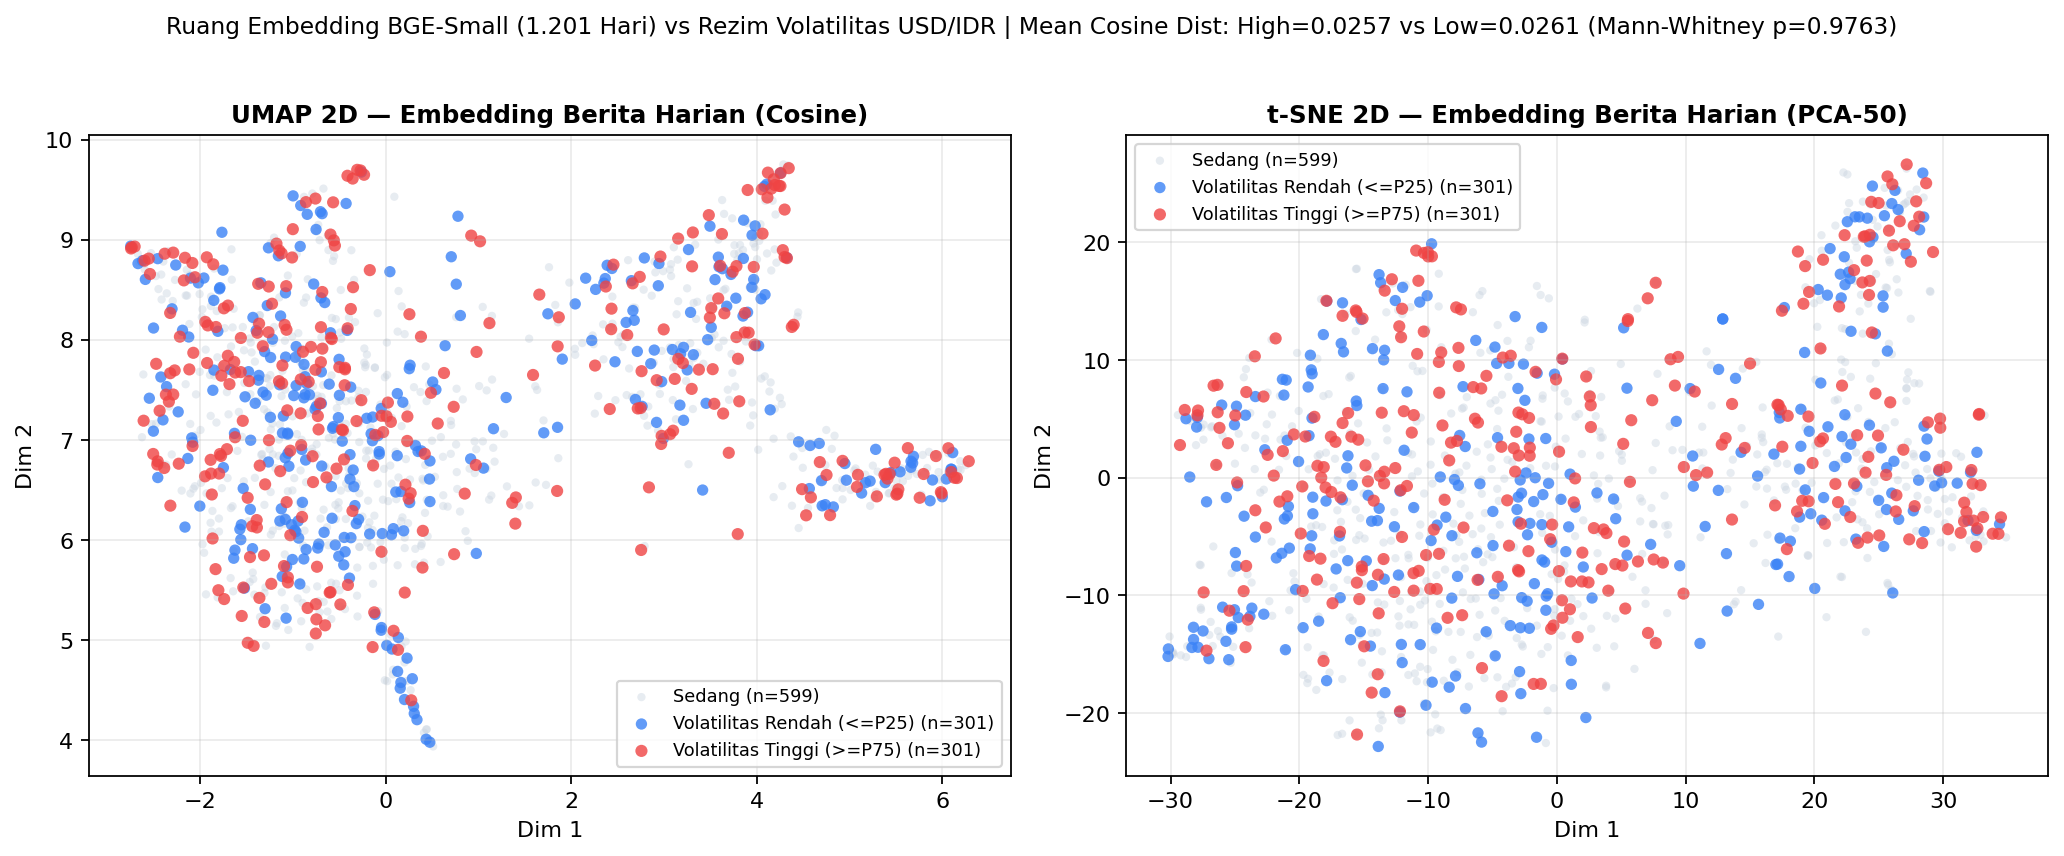

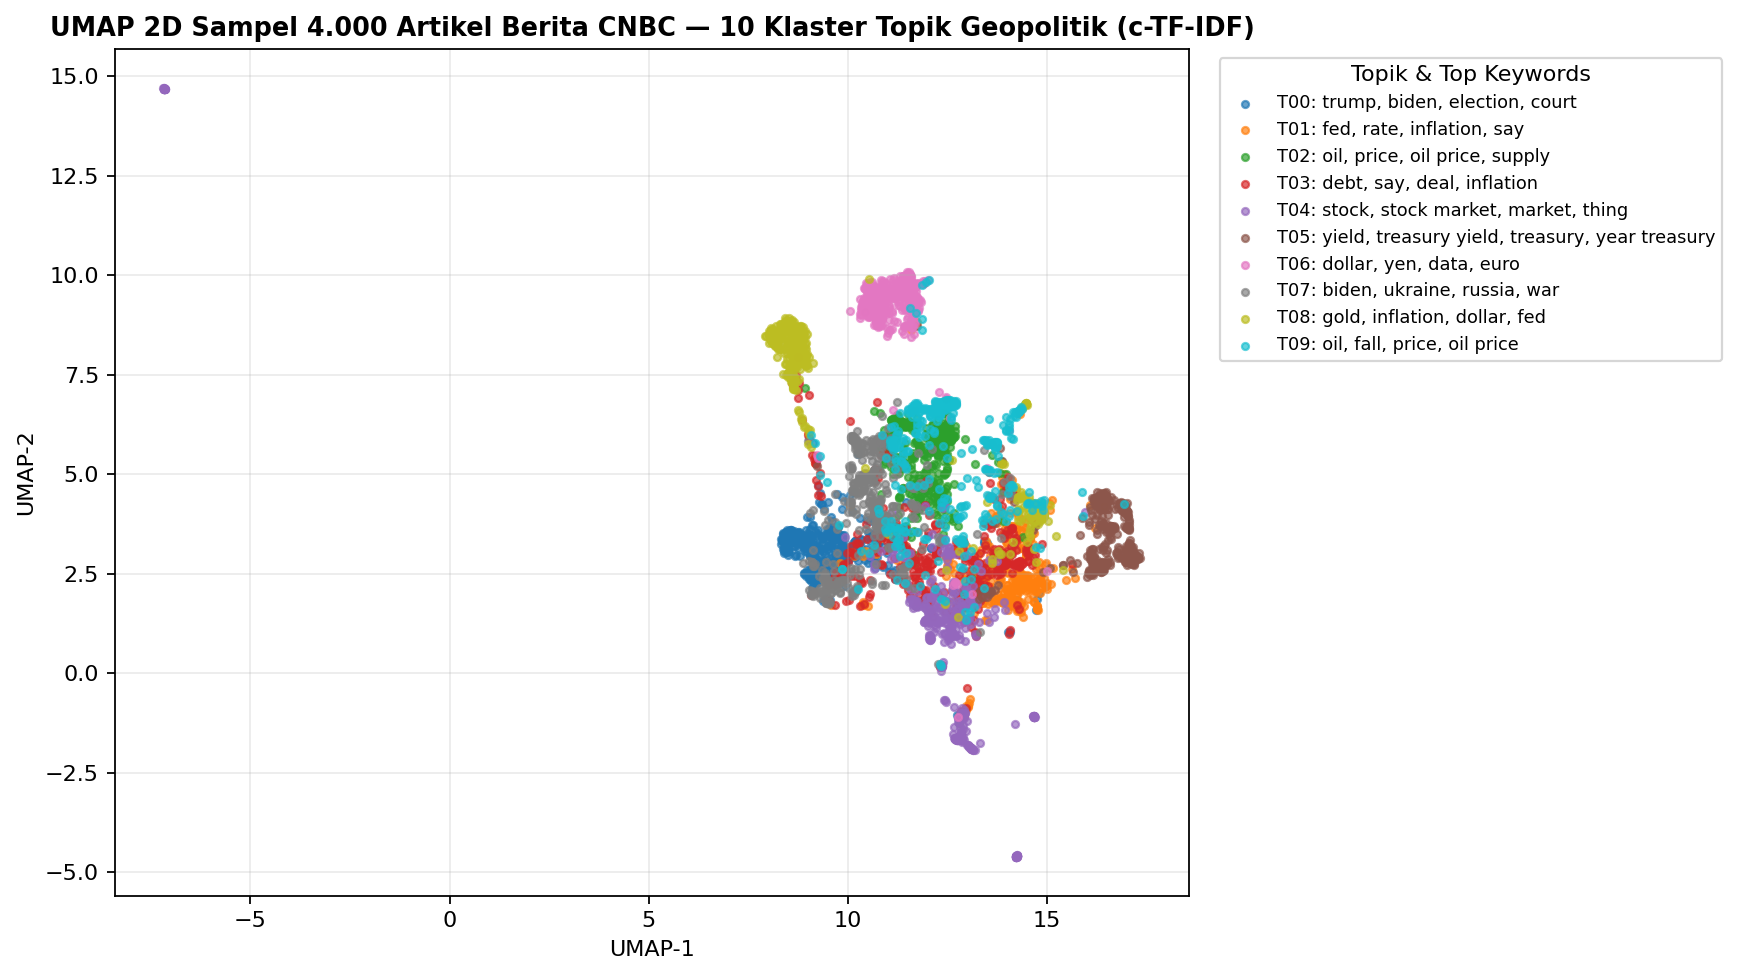

In [9]:
display(Image(filename=str(FIG / "fig1_embedding_volatility_umap_tsne.png")))
display(Image(filename=str(FIG / "fig2_articles_topics_umap.png")))

---

## 6. Analisis Wajib 2: Feature Importance & Interpretabilitas (`SHAP`)
Menilai kontribusi setiap fitur dan grup modalitas pada model tree Early Fusion terbaik (`early:xgb:time_ext+bge_raw384+topic`) serta besaran koefisien pada cabang teks `LogReg` compact FE.

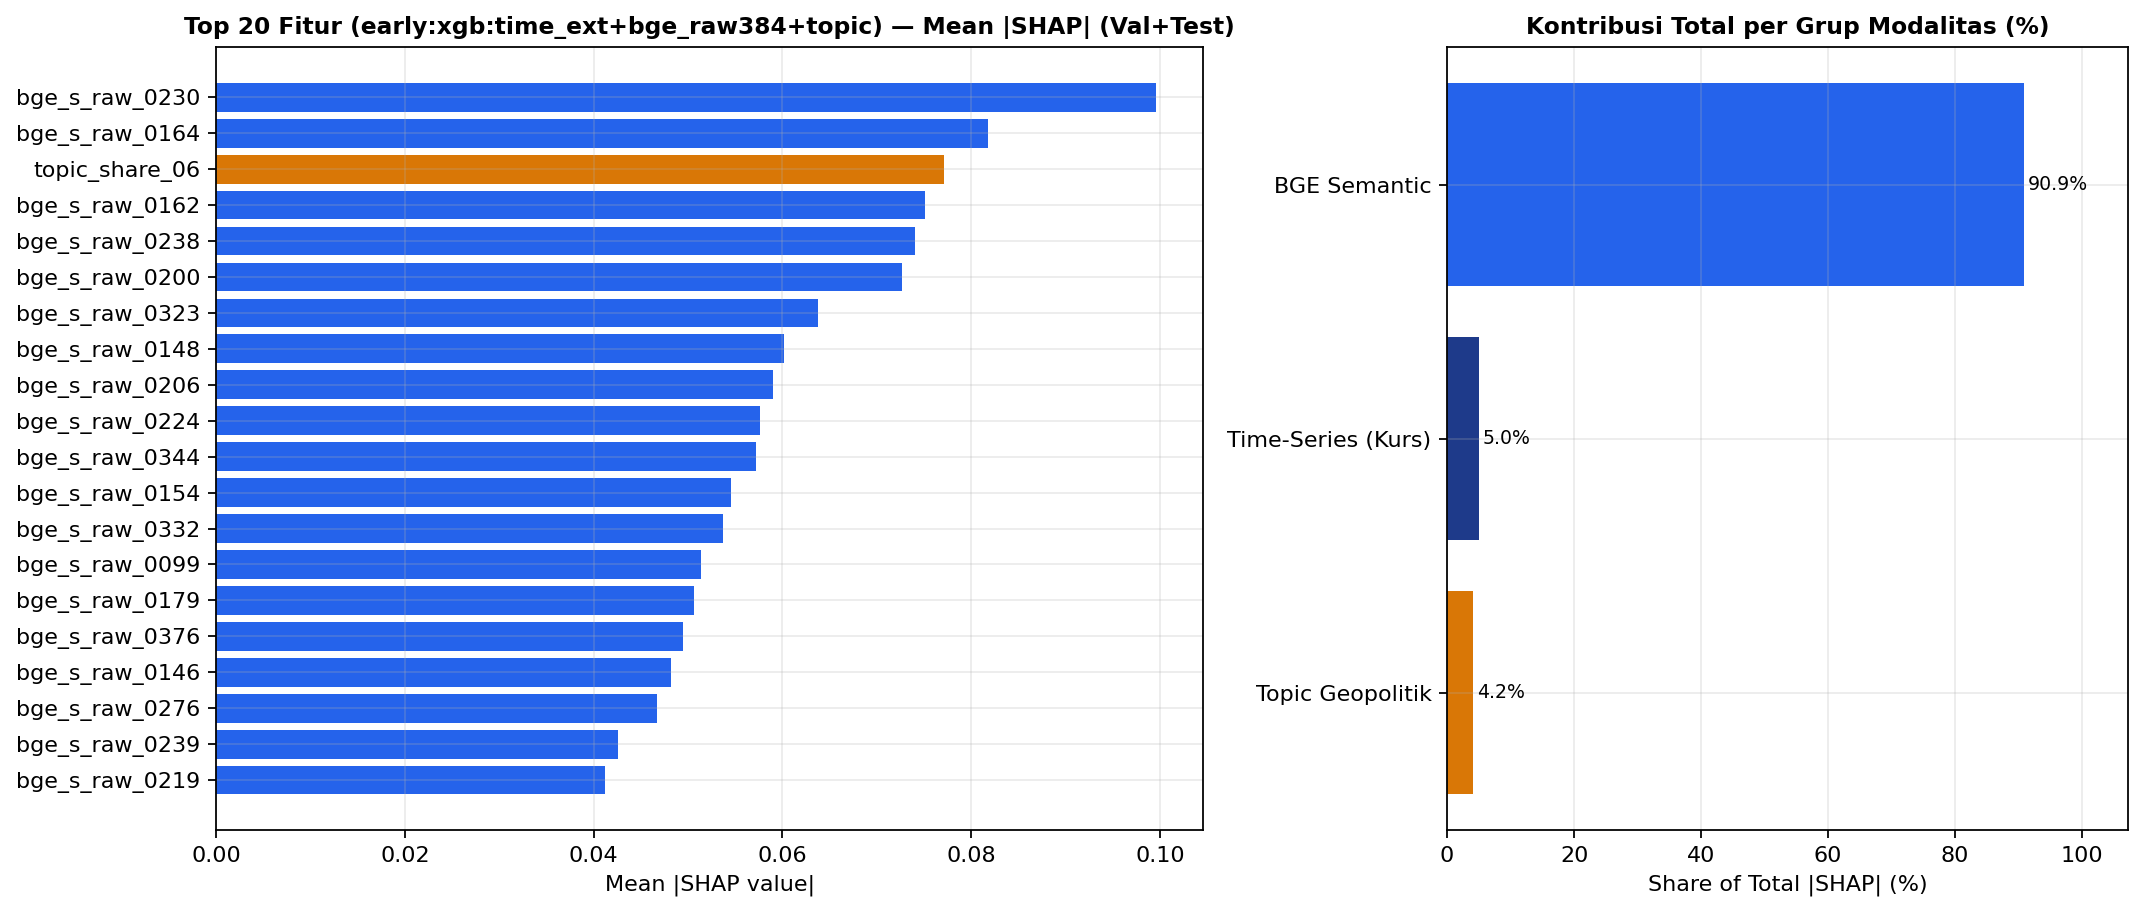

Top 15 Fitur berdasarkan Mean |SHAP| (Tree Early Fusion):


,feature,modality_group,mean_abs_shap,share_pct
0,bge_s_raw_0230,BGE Semantic,0.0996,2.1150
1,bge_s_raw_0164,BGE Semantic,0.0818,1.7367
2,topic_share_06,Topic Geopolitik,0.0771,1.6362
3,bge_s_raw_0162,BGE Semantic,0.0751,1.5954
4,bge_s_raw_0238,BGE Semantic,0.0740,1.5710
5,bge_s_raw_0200,BGE Semantic,0.0727,1.5427
6,bge_s_raw_0323,BGE Semantic,0.0638,1.3548
7,bge_s_raw_0148,BGE Semantic,0.0602,1.2776
8,bge_s_raw_0206,BGE Semantic,0.0590,1.2524
9,bge_s_raw_0224,BGE Semantic,0.0576,1.2234


Top 15 Fitur Terinterpretasi pada Cabang Teks (LogReg Full Compact FE):


,feature,modality_group,abs_logreg_coef
0,vader_comp_ewma5,EWMA & News Shock,0.6693
1,vader_comp_ewma3,EWMA & News Shock,0.6050
2,topic_share_01,Topic Geopolitik,0.4609
3,bge_raw_pca16_00,BGE Semantic,0.4384
4,lm_uncert_ewma5,EWMA & News Shock,0.4045
5,lm_uncert_ewma3,EWMA & News Shock,0.3465
6,topic_share_07,Topic Geopolitik,0.3456
7,bge_raw_pca16_02,BGE Semantic,0.3337
8,topic_ent_ewma3,Topic Geopolitik,0.3267
9,fb_soft_share_neg,NER & FinBERT Sentimen,0.3116


In [10]:
display(Image(filename=str(FIG / "fig3_shap_importance.png")))

imp_df = pd.read_csv(RES / "tugas3_feature_importance.csv")
lr_imp = pd.read_csv(RES / "tugas3_text_branch_coef_importance.csv")

print("Top 15 Fitur berdasarkan Mean |SHAP| (Tree Early Fusion):")
display(imp_df.head(15).round(4))

print("Top 15 Fitur Terinterpretasi pada Cabang Teks (LogReg Full Compact FE):")
display(lr_imp.head(15).round(4))

---

## 7. Analisis Wajib 3: Korelasi Fitur NLP, Distribusi Error, & Case Study Tanggal Spesifik
Menganalisis korelasi fitur ringkas NLP terhadap `ret_pct` (arah) dan `|ret_pct|` (volatilitas), membandingkan akurasi di tiap kuartil volatilitas / hari kerja / arah aktual, serta menelaah tanggal-tanggal test spesifik saat **NLP membantu menghindari sinyal palsu teknikal** vs saat **teks justru menambah noise**.

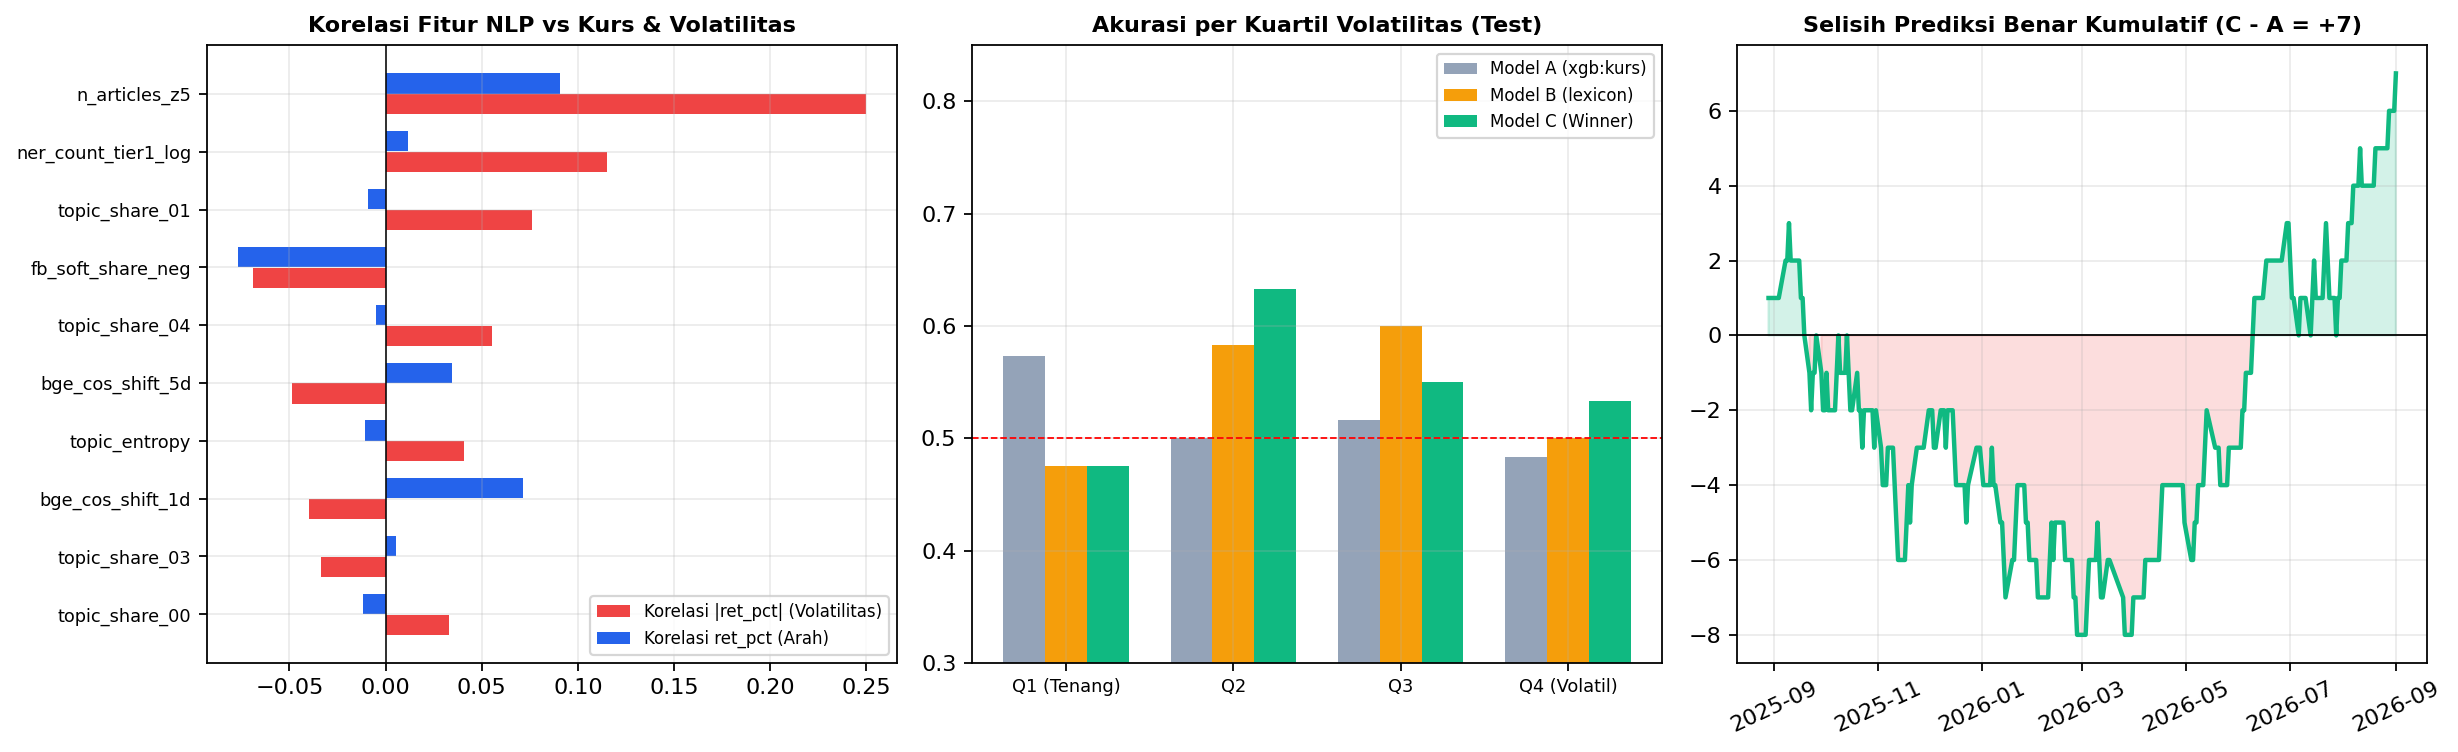

Korelasi Fitur NLP vs Return Kurs & Volatilitas (1.201 Hari):


,feature,pearson_ret,pval_ret,pearson_abs_ret,pval_abs_ret,spearman_abs_ret
0,n_articles_z5,0.0909,0.0016,0.2496,0.0000,0.0731
1,ner_count_tier1_log,0.0117,0.6863,0.1153,0.0001,0.0415
2,topic_share_01,-0.0092,0.7502,0.0762,0.0082,0.0581
3,fb_soft_share_neg,-0.0766,0.0079,-0.0691,0.0166,-0.0642
4,topic_share_04,-0.0050,0.8639,0.0553,0.0554,0.0333
5,bge_cos_shift_5d,0.0345,0.2327,-0.0488,0.0910,-0.0003
6,topic_entropy,-0.0106,0.7130,0.0406,0.1595,0.0270
7,bge_cos_shift_1d,0.0716,0.0131,-0.0396,0.1704,-0.0076
8,topic_share_03,0.0053,0.8540,-0.0333,0.2482,-0.0255
9,topic_share_00,-0.0118,0.6836,0.0328,0.2566,0.0860


Distribusi Akurasi per Segmen di Split Test (Model A vs B vs C):


,dimension,segment,n,DA_ModelA_kurs,DA_ModelB_lex,DA_ModelC,delta_C_vs_A
0,vol_quartile,Q1 (Tenang),61,0.5738,0.4754,0.4754,-0.0984
1,vol_quartile,Q2,60,0.5000,0.5833,0.6333,0.1333
2,vol_quartile,Q3,60,0.5167,0.6000,0.5500,0.0333
3,vol_quartile,Q4 (Volatil),60,0.4833,0.5000,0.5333,0.0500
4,day_group,Selasa-Jumat,192,0.5208,0.5312,0.5521,0.0312
5,day_group,Senin (Akumulasi Wknd),49,0.5102,0.5714,0.5306,0.0204
6,actual_dir,y=0 (IDR Menguat/Tetap),103,0.2136,0.2718,0.4466,0.2330
7,actual_dir,y=1 (IDR Melemah),138,0.7464,0.7391,0.6232,-0.1232


Case Study Top Tanggal Test (NLP Menyelamatkan vs NLP Menambah Noise):


,case_type,date,ret_pct,y,pred_model_a_kurs,pred_model_c,prob_model_c,dom_topic_keywords,top_headlines
0,"NLP_Menyelamatkan (A salah, C benar)",2026-06-10,-0.9371,0,1,0,0.0685,"trump, biden, election, court, case, judge, ho...",[T2] Inflation data threatens to derail market...
1,"NLP_Menyelamatkan (A salah, C benar)",2025-08-29,0.6420,1,0,1,0.7536,"trump, biden, election, court, case, judge, ho...",[T2] Oil settles higher as traders await Trump...
2,"NLP_Menyelamatkan (A salah, C benar)",2026-06-29,-0.5901,0,1,0,0.4138,"stock, stock market, market, thing, wall, wall...","[T2] U.S. crude oil falls below $70, resuming ..."
3,"NLP_Menyelamatkan (A salah, C benar)",2026-05-12,0.5685,1,0,1,0.7485,"stock, stock market, market, thing, wall, wall...",[T2] China inflation beat estimates in April a...
4,"NLP_Menyelamatkan (A salah, C benar)",2026-03-10,-0.5597,0,1,0,0.1046,"oil, price, oil price, supply, gas, opec, ener...",[T2] Why China can withstand oil's surge past ...
5,"NLP_Menyelamatkan (A salah, C benar)",2025-09-08,-0.5475,0,1,0,0.1752,"trump, biden, election, court, case, judge, ho...","[T2] Gold slips after record rally, U.S. payro..."
6,"NLP_Menyelamatkan (A salah, C benar)",2025-10-09,-0.4336,0,1,0,0.0868,"debt, say, deal, inflation, recession, cnbc, y...",[T2] European stocks close higher after EU pro...
7,"NLP_Menyelamatkan (A salah, C benar)",2025-10-02,-0.4077,0,1,0,0.0944,"debt, say, deal, inflation, recession, cnbc, y...",[T2] U.S. government shuts down after midnight...
8,"NLP_Menambah_Noise (A benar, C salah)",2026-05-18,0.9717,1,1,0,0.1080,"biden, ukraine, russia, war, say, china, israe...",[T2] Analysis: Iran war hangs over Trump's Chi...
9,"NLP_Menambah_Noise (A benar, C salah)",2025-09-29,-0.5663,0,0,1,0.8504,"trump, biden, election, court, case, judge, ho...",[T2] Cramer's week ahead: Nonfarm payroll repo...


In [11]:
display(Image(filename=str(FIG / "fig4_error_and_correlation.png")))

corr_df = pd.read_csv(RES / "tugas3_nlp_kurs_correlations.csv")
bd_df = pd.read_csv(RES / "tugas3_error_breakdown.csv")
cases_df = pd.read_csv(RES / "tugas3_error_case_studies.csv")

print("Korelasi Fitur NLP vs Return Kurs & Volatilitas (1.201 Hari):")
display(corr_df.sort_values("pval_abs_ret").round(4).reset_index(drop=True))

print("Distribusi Akurasi per Segmen di Split Test (Model A vs B vs C):")
display(bd_df.round(4))

print("Case Study Top Tanggal Test (NLP Menyelamatkan vs NLP Menambah Noise):")
show_cols = ["case_type", "date", "ret_pct", "y", "pred_model_a_kurs", "pred_model_c", "prob_model_c", "dom_topic_keywords", "top_headlines"]
display(cases_df[show_cols].round(4))

---

## 8. Kesimpulan & Rekap Temuan Tugas 3
1. **Perbandingan 3 Kategori Feature Extraction (Tahap 1):** Dengan *simple mean pooling* identik, **`BAAI/bge-small-en-v1.5` (`384D`)** unggul di `test` (**DA `0.5768`**, **F1 macro `0.5258`**) dibanding `FastText` (`0.5062` best-val / `0.5270` raw), `ProsusAI/finbert` (`0.5353`), maupun `baai/bge-large-en-v1.5` (`0.5643`).
2. **Dampak Feature Engineering (Tahap 2A–2B):**
   - **NER Tiered Weighting** sukses memulihkan sinyal sentimen `FinBERT` yang sebelumnya tenggelam (`F1 macro test`: `0.4299 -> 0.5099`).
   - **Topic Modeling** berbasis `bge-small` menghasilkan 10 tema makro-geopolitik yang tajam secara visual di UMAP, dengan **`topic_share_06` (*dollar, yen, data, euro, fed*)** masuk 3 besar fitur terpenting `SHAP`.
   - Lonjakan volume berita (`n_articles_z5`, $r = +0.250, p = 1.6 \times 10^{-18}$) dan jumlah artikel Tier-1 (`ner_count_tier1_log`, $r = +0.115, p = 6.2 \times 10^{-5}$) berkorelasi paling signifikan terhadap **volatilitas** harian USD/IDR (`|ret_pct|`).
3. **Dampak Multimodal Fusion (Tahap 2C — Pemenang Model C):**
   - Di `Early Fusion` berbasis pohon (`XGBoost`), 384 dimensi teks mendominasi (`90.9%` total SHAP vs `5.0%` fitur kurs) sehingga rentan bias kelas mayoritas.
   - **`Late Fusion (Prob): logreg_bge_soft384 + xgb_ext` ($\alpha_{\text{text}} = 0.85$)** dan varian **Logit ($\alpha = 0.80$)** menyelesaikan ketimpangan dimensi tersebut: terpilih terbaik di `val` (**DA `0.5792`**, **F1 `0.5770`**) dan mencatat **F1 macro test paling sehat (`0.5349` / `0.5398`)** dibanding Model A `xgb:kurs` (`DA 0.5187`, `F1 0.4574`) maupun Model B `xgb:kurs+lexicon` (`DA 0.5394`, `F1 0.4915`).
   - Peningkatan terbesar Model C terjadi pada kemampuannya mendeteksi hari penguatan Rupiah (`y=0`: **`44.66%` vs `21.36%`** pada Model A, +23.3 poin) serta hari bervolatilitas tinggi (`Q4`: **`53.33%` vs `48.33%`**).